# TP2 — Parte 1: Dataset, EDA, Control de Calidad y Preprocesamiento

Notebook de análisis y preparación del **70 Dog Breeds Image Dataset** (ver `ENUNCIADO.md`, sección 3).
Incluye EDA completo, reglas explícitas y reproducibles de filtrado, detección de duplicados y fuga de datos,
estructura y auditoría del conjunto independiente, preprocesamiento compartido (`src/lib/preprocessing.py`),
data augmentation on-the-fly (`albumentations`) y exportación de `data/splits.csv` para `2-train.ipynb`.

**Notebook en Google Colab:** https://colab.research.google.com/drive/1l-LYB9LC1u36usQXq-s_x5J1uF9YtYNm?usp=sharing

## Equipo
- **Emanuel Speranza** — `@Manuspe`

## 1. Clonar el repositorio y configurar almacenamiento (Colab / Local)

In [18]:
import os
from pathlib import Path

REPO_URL = "https://github.com/Manuspe/tuia-dog-recognition-app.git"
BRANCH = "feature/tp2-razas-perros"

# Detectar
if (Path.cwd() / "src" / "lib").is_dir():
    ROOT = Path.cwd()
elif (Path("/content/proyecto/src/lib")).is_dir():
    ROOT = Path("/content/proyecto")
    %cd /content/proyecto
else:
    !git clone -b $BRANCH $REPO_URL /content/proyecto
    ROOT = Path("/content/proyecto")
    %cd /content/proyecto

# Activar Google Drive para persistir splits.csv y el conjunto independiente
USE_DRIVE = True
DRIVE_DIR = Path("/content/drive/MyDrive/TP2_Perros")
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("Directorio de trabajo:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de trabajo: /content/proyecto


In [19]:
!unzip -q -o /content/drive/MyDrive/TP2_Perros/independent_dataset.zip -d /content/proyecto/data/dataset/

## 2. Instalar dependencias

In [20]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations==2.0.8 onnxruntime "ultralytics>=8.4.0" seaborn

## 3. Configuración del entorno y semillas

In [21]:
import random
import sys
import numpy as np
import torch

os.environ["USE_PGVECTOR"] = "false"
os.environ["IMAGE_SIZE"] = "224"
os.environ["EMBEDDING_DIM"] = "512"
os.environ["BASELINE_MODEL_NAME"] = "resnet18"
os.environ["DATA_PATH"] = str(ROOT / "data")
os.environ["DATASET_PATH"] = str(ROOT / "data" / "dataset")
os.environ["SPLITS_PATH"] = str(ROOT / "data" / "splits.csv")
os.environ["OUTPUT_PATH"] = str(ROOT / "output")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

SEED = settings.random_seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("dataset_path:", settings.dataset_path)
print("splits_path:", settings.splits_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: /content/proyecto/data/dataset
splits_path: /content/proyecto/data/splits.csv
GPU disponible: True


## 4. Descarga del dataset y verificación de nombres de carpetas

In [22]:
!python scripts/download_dataset.py

# Verificacion del bug conocido de Kaggle: carpeta 'valid/American  Spaniel' (doble espacio)
double_space_dir = settings.dataset_path / "valid" / "American  Spaniel"
clean_dir = settings.dataset_path / "valid" / "American Spaniel"
if double_space_dir.is_dir() and not clean_dir.exists():
    double_space_dir.rename(clean_dir)
    print("Carpeta renombrada: 'American  Spaniel' -> 'American Spaniel'")

for split_name in ("train", "valid", "test"):
    p = settings.dataset_path / split_name
    n_breeds = len([d for d in p.iterdir() if d.is_dir()]) if p.is_dir() else 0
    print(f"{split_name}: {n_breeds} carpetas de razas")

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Ya existe, se omite: /content/proyecto/data/dataset/valid
Ya existe, se omite: /content/proyecto/data/dataset/dogs.csv
Ya existe, se omite: /content/proyecto/data/dataset/test
Ya existe, se omite: /content/proyecto/data/dataset/train
Dataset disponible en /content/proyecto/data/dataset
train: 70 carpetas de razas
valid: 70 carpetas de razas
test: 70 carpetas de razas


## 5. Descripción del dataset y limitaciones

- **Dataset:** *70 Dog Breeds Image Dataset* (Gerry / gpiosenka en Kaggle).
- **Estructura original:** 70 razas divididas en `train/`, `valid/` (10 imágenes por raza) y `test/` (10 imágenes por raza), además de `dogs.csv`.
- **Encuadre vs. Etapa 3 (cambio de dominio):** las imágenes del dataset suelen estar centradas en el perro (primeros planos faciales o cuerpo completo con encuadre relativamente limpio), mientras que en la Etapa 3 el clasificador recibe **recortes generados por YOLO**, que presentan proporciones más extremas, oclusiones parciales, fondos urbanos/domésticos variados y resoluciones variables.
- **Limitaciones explícitas:**
  1. Desbalance moderado en `train` (aprox. entre 65 y 198 imágenes por raza).
  2. Razas visualmente muy cercanas (p. ej., *Bulldog* / *French Bulldog* / *Boston Terrier*, *Lhasa* / *Shih-Tzu*, *Cocker* / *American Spaniel*, *Cairn* / *Yorkie*).
  3. Sesgos de origen web (fotos de estudio, poses posadas, marcas de agua ocasionales) y **ausencia de perros mestizos** o clase *unknown* explícita.

In [23]:
import pandas as pd
from lib.splits import IMAGE_SUFFIXES, normalize_breed_name

records = []
for split_name in ("train", "valid", "test"):
    split_dir = settings.dataset_path / split_name
    for breed_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        breed = normalize_breed_name(breed_dir.name)
        for f in sorted(breed_dir.iterdir()):
            if f.is_file():
                records.append({
                    "split": split_name,
                    "breed": breed,
                    "path": f,
                    "rel_path": f.relative_to(settings.dataset_path).as_posix(),
                    "ext": f.suffix.lower(),
                })

df_raw = pd.DataFrame(records)
print(f"Total archivos encontrados: {len(df_raw)} | Razas unicas: {df_raw['breed'].nunique()}")
print("Extensiones:", df_raw["ext"].value_counts().to_dict())
display(df_raw.groupby("split")["breed"].agg(imagenes="count", razas="nunique"))

Total archivos encontrados: 9346 | Razas unicas: 70
Extensiones: {'.jpg': 9346}


,imagenes,razas
split,,
test,700,70
train,7946,70
valid,700,70


## 6. Análisis Exploratorio de Datos (EDA)

Analizamos distribución de clases (y suficiencia estadística de `valid`/`test` con 10 imágenes/raza), resoluciones, relación de aspecto, canales, ejemplos visuales de pares confundibles y variaciones de iluminación.

split,train,valid,test
mean,113.51,10.0,10.0
median,111.50,10.0,10.0
min,65.00,10.0,10.0
max,198.00,10.0,10.0
std,24.68,0.0,0.0


Ratio de desbalance en train (max/min): 3.05x


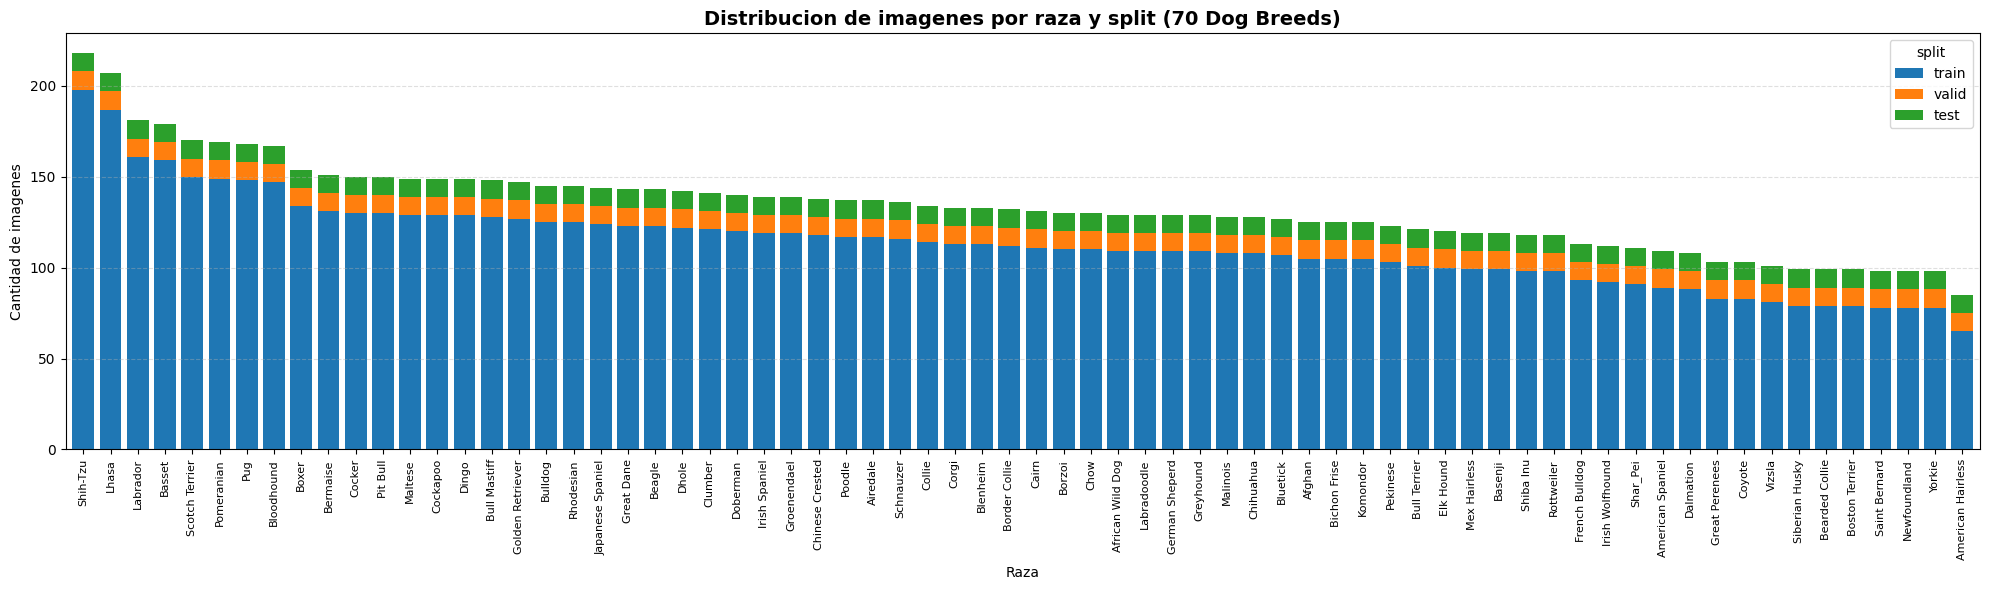

In [24]:
import matplotlib.pyplot as plt

counts = df_raw.groupby(["breed", "split"]).size().unstack(fill_value=0)[["train", "valid", "test"]]
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("train", ascending=False)

stats_df = counts[["train", "valid", "test"]].agg(["mean", "median", "min", "max", "std"]).round(2)
display(stats_df)
print(f"Ratio de desbalance en train (max/min): {counts['train'].max() / counts['train'].min():.2f}x")

fig, ax = plt.subplots(figsize=(20, 6))
counts[["train", "valid", "test"]].plot(kind="bar", stacked=True, ax=ax, width=0.8)
ax.set_title("Distribucion de imagenes por raza y split (70 Dog Breeds)", fontsize=14, fontweight="bold")
ax.set_xlabel("Raza")
ax.set_ylabel("Cantidad de imagenes")
plt.xticks(rotation=90, fontsize=8)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Inspeccionando imagenes:   0%|          | 0/9346 [00:00<?, ?it/s]

Imagenes corruptas/ilegibles: 0
Canales: {3: 9346}


,width,height,aspect,lap_var,brightness,contrast
count,9346.0,9346.0,9346.0,9346.00,9346.00,9346.00
mean,224.0,224.0,1.0,1643.85,125.65,58.23
std,0.0,0.0,0.0,1891.94,31.24,13.25
min,224.0,224.0,1.0,24.74,27.69,16.46
25%,224.0,224.0,1.0,542.74,106.22,49.30
50%,224.0,224.0,1.0,1073.23,123.76,57.77
75%,224.0,224.0,1.0,2030.85,141.22,66.11
max,224.0,224.0,1.0,36934.60,243.05,111.32


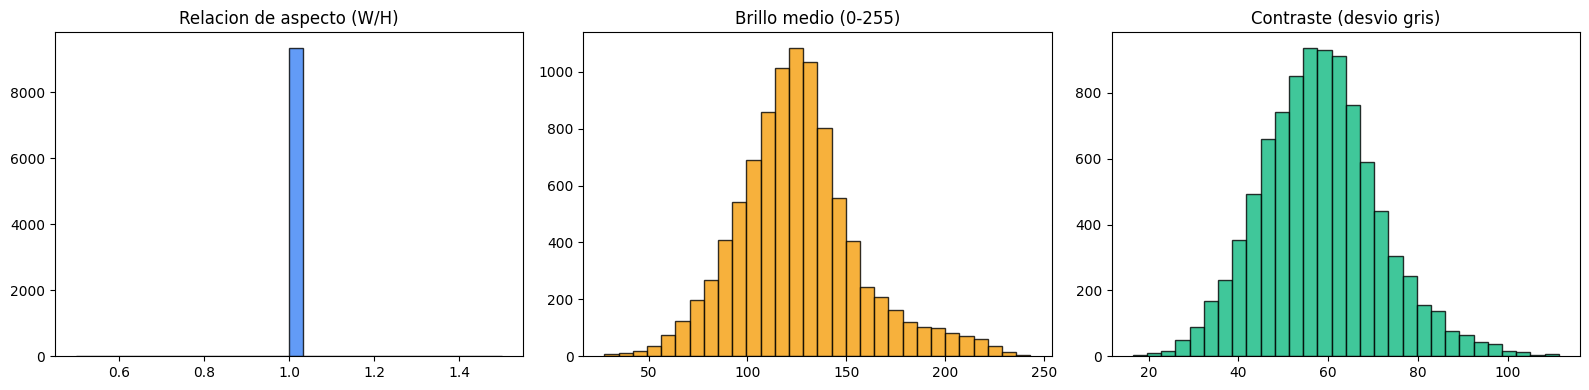

In [25]:
import cv2
import hashlib
from tqdm.auto import tqdm

def compute_dhash(gray: np.ndarray, hash_size: int = 8) -> int:
    resized = cv2.resize(gray, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    diff = resized[:, 1:] > resized[:, :-1]
    return sum((1 << i) for i, val in enumerate(diff.flatten()) if val)

meta_rows = []
for row in tqdm(df_raw.itertuples(index=False), total=len(df_raw), desc="Inspeccionando imagenes"):
    img_path = row.path
    img = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)
    if img is None or img.size == 0:
        meta_rows.append({
            "corrupt": True, "width": 0, "height": 0, "channels": 0,
            "aspect": 0.0, "lap_var": 0.0, "brightness": 0.0, "contrast": 0.0,
            "sha256": "", "dhash": -1,
        })
        continue

    h, w = img.shape[:2]
    c = 1 if img.ndim == 2 else img.shape[2]
    if img.ndim == 2:
        gray = img
    elif c == 4:
        gray = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY)
    else:
        gray = cv2.cvtColor(img[:, :, :3], cv2.COLOR_BGR2GRAY)

    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    brightness = float(gray.mean())
    contrast = float(gray.std())
    sha = hashlib.sha256(img_path.read_bytes()).hexdigest()
    dhash = compute_dhash(gray)
    meta_rows.append({
        "corrupt": False, "width": w, "height": h, "channels": c,
        "aspect": w / max(h, 1), "lap_var": lap_var,
        "brightness": brightness, "contrast": contrast,
        "sha256": sha, "dhash": dhash,
    })

df_eda = pd.concat([df_raw.reset_index(drop=True), pd.DataFrame(meta_rows)], axis=1)
valid_eda = df_eda[~df_eda["corrupt"]]
print(f"Imagenes corruptas/ilegibles: {df_eda['corrupt'].sum()}")
print("Canales:", valid_eda["channels"].value_counts().to_dict())
display(valid_eda[["width", "height", "aspect", "lap_var", "brightness", "contrast"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(valid_eda["aspect"], bins=30, color="#3b82f6", edgecolor="black", alpha=0.8)
axes[0].set_title("Relacion de aspecto (W/H)")
axes[1].hist(valid_eda["brightness"], bins=30, color="#f59e0b", edgecolor="black", alpha=0.8)
axes[1].set_title("Brillo medio (0-255)")
axes[2].hist(valid_eda["contrast"], bins=30, color="#10b981", edgecolor="black", alpha=0.8)
axes[2].set_title("Contraste (desvio gris)")
plt.tight_layout()
plt.show()

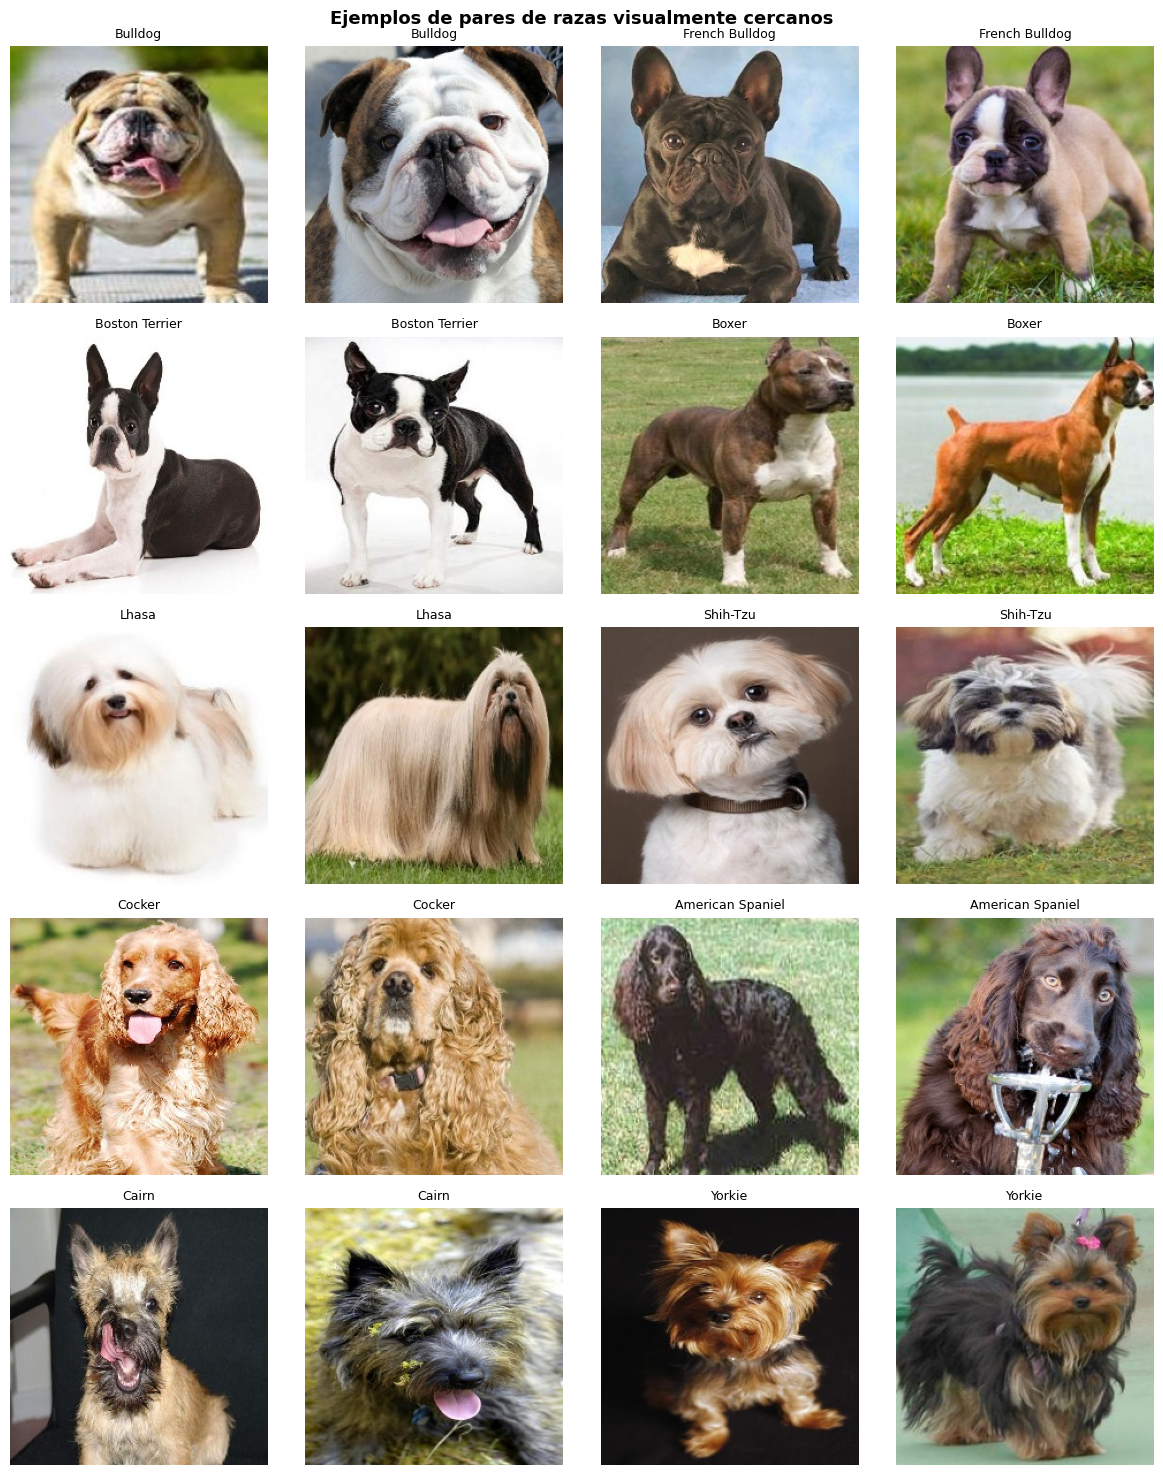

In [26]:
# Muestra visual de pares de razas faciles de confundir
confusable_pairs = [
    ("Bulldog", "French Bulldog"),
    ("Boston Terrier", "Boxer"),
    ("Lhasa", "Shih-Tzu"),
    ("Cocker", "American Spaniel"),
    ("Cairn", "Yorkie"),
]

fig, axes = plt.subplots(len(confusable_pairs), 4, figsize=(12, 3 * len(confusable_pairs)))
for r, (b1, b2) in enumerate(confusable_pairs):
    for col_offset, breed in enumerate([b1, b2]):
        sub = valid_eda[(valid_eda["breed"] == breed) & (valid_eda["split"] == "train")].head(2)
        for k in range(2):
            ax = axes[r, col_offset * 2 + k]
            if k < len(sub):
                bgr = cv2.imread(str(sub.iloc[k]["path"]))
                ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
                ax.set_title(breed, fontsize=9)
            ax.axis("off")
plt.suptitle("Ejemplos de pares de razas visualmente cercanos", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Control de calidad y filtrado reproducible

Definimos reglas explícitas aplicadas sobre **todos los splits (`train`, `valid`, `test`)** con orden de prioridad **`test` → `valid` → `train`**:
1. **Corruptas / ilegibles** (`corrupt == True`).
2. **Baja resolución** (`min(width, height) < 64`).
3. **Borrosas o exposición extrema** (`lap_var < 20.0` o `brightness < 12.0` o `brightness > 243.0`).
4. **Duplicados exactos (SHA256) y casi-duplicados (dHash Hamming ≤ 3)**:
   - **Intra-split:** se conserva la primera aparición y se eliminan copias repetidas (incluyendo 4 duplicados exactos en `test` y 1 en `valid`) para evitar métricas artificialmente infladas por repeticiones.
   - **Inter-split (fuga de datos):** como `test` y `valid` tienen mayor prioridad de conservación, cualquier coincidencia con `train` (y de `valid` con `test`) se descarta del split de menor prioridad para preservar la integridad de evaluación.

Total descartadas: 234 de 9346


split,test,train,valid
discard_reason,,,
casi_duplicado_dhash,0,84,2
duplicado_intra_sha,4,38,1
exposicion_extrema,0,1,0
fuga_inter_split_dhash,0,24,4
fuga_inter_split_sha,0,70,6


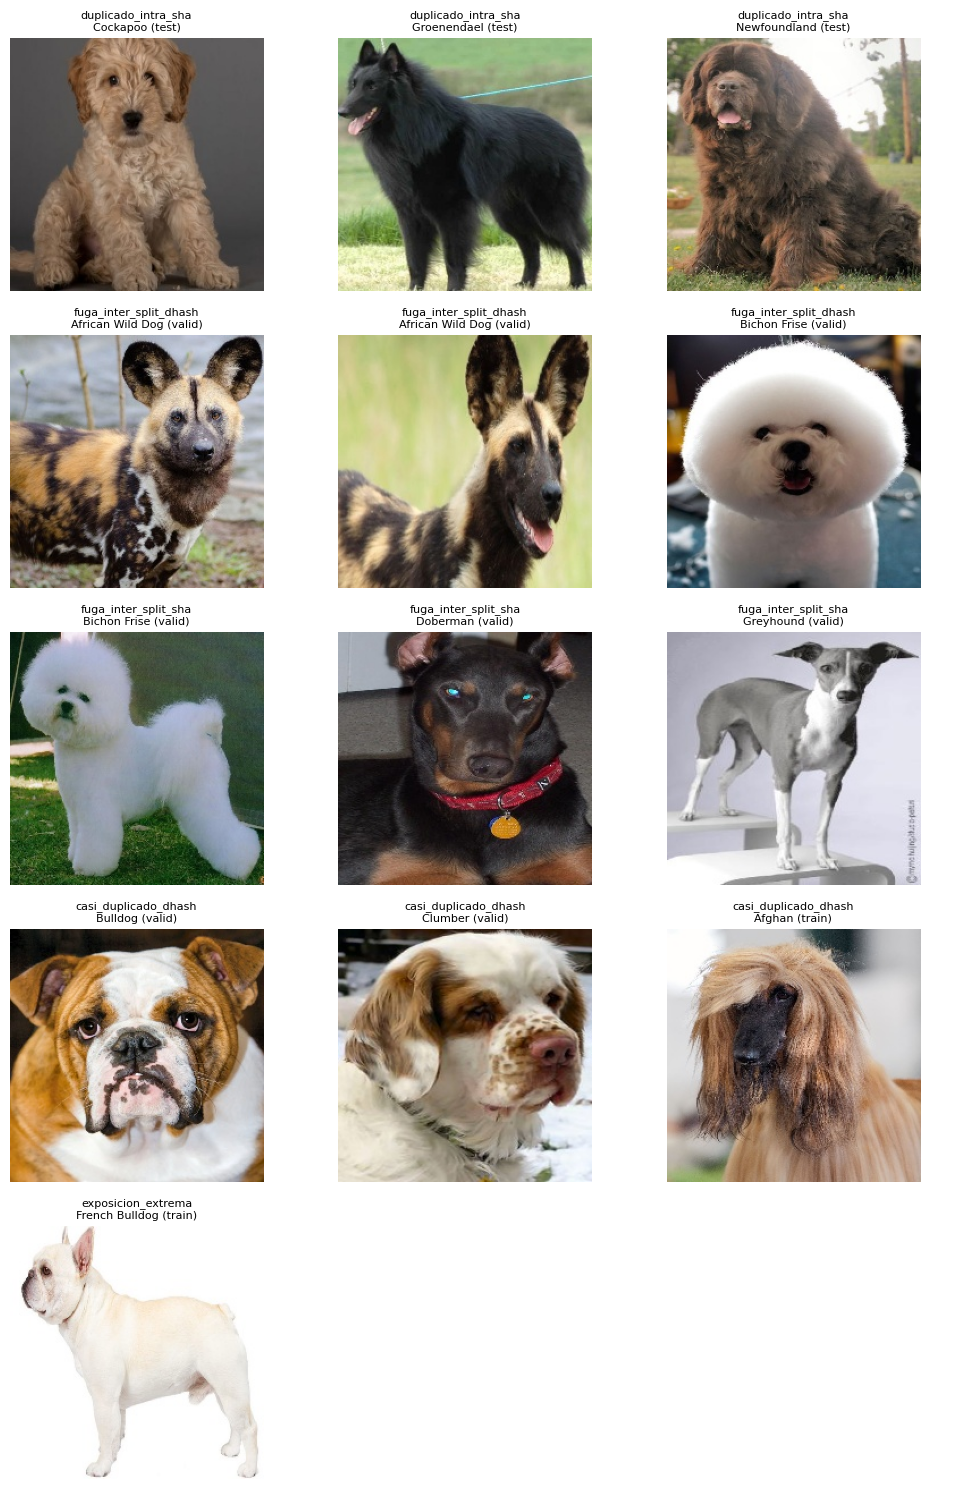

In [27]:
MIN_SIDE = 64
MIN_LAP_VAR = 20.0
MIN_BRIGHT = 12.0
MAX_BRIGHT = 243.0
DHASH_MAX_DIST = 3

df_qc = df_eda.copy()
df_qc["discard_reason"] = ""

def flag_reason(mask, reason):
    empty = df_qc["discard_reason"] == ""
    df_qc.loc[empty & mask, "discard_reason"] = reason

flag_reason(df_qc["corrupt"], "corrupta_o_ilegible")
flag_reason(df_qc[["width", "height"]].min(axis=1) < MIN_SIDE, f"baja_resolucion(<{MIN_SIDE}px)")
flag_reason(df_qc["lap_var"] < MIN_LAP_VAR, f"borrosa(lap<{MIN_LAP_VAR})")
flag_reason((df_qc["brightness"] < MIN_BRIGHT) | (df_qc["brightness"] > MAX_BRIGHT), "exposicion_extrema")

# Duplicados exactos (prioridad de conservacion: test -> valid -> train)
priority_order = {"test": 0, "valid": 1, "train": 2}
df_qc["prio"] = df_qc["split"].map(priority_order)
df_qc = df_qc.sort_values(["prio", "rel_path"]).reset_index(drop=True)

seen_sha = {}
seen_dhash = []  # (dhash, split, idx)
for idx, row in df_qc.iterrows():
    if row["discard_reason"] != "":
        continue
    sha = row["sha256"]
    if sha in seen_sha:
        other_split = seen_sha[sha]
        df_qc.at[idx, "discard_reason"] = (
            "fuga_inter_split_sha" if other_split != row["split"] else "duplicado_intra_sha"
        )
        continue
    seen_sha[sha] = row["split"]

    dh = int(row["dhash"])
    matched_split = None
    for prev_dh, prev_split in seen_dhash:
        if (dh ^ prev_dh).bit_count() <= DHASH_MAX_DIST:
            matched_split = prev_split
            break
    if matched_split is not None:
        df_qc.at[idx, "discard_reason"] = (
            "fuga_inter_split_dhash" if matched_split != row["split"] else "casi_duplicado_dhash"
        )
    else:
        seen_dhash.append((dh, row["split"]))

discarded = df_qc[df_qc["discard_reason"] != ""]
print(f"Total descartadas: {len(discarded)} de {len(df_qc)}")
display(discarded.groupby(["discard_reason", "split"]).size().unstack(fill_value=0))

# Muestra visual de ejemplos descartados por regla
reasons = [r for r in discarded["discard_reason"].unique() if r != "corrupta_o_ilegible"]
if reasons:
    fig, axes = plt.subplots(len(reasons), 3, figsize=(10, 3 * len(reasons)))
    if len(reasons) == 1:
        axes = np.expand_dims(axes, axis=0)
    for r_idx, reason in enumerate(reasons):
        sub = discarded[discarded["discard_reason"] == reason].head(3)
        for c_idx in range(3):
            ax = axes[r_idx, c_idx]
            if c_idx < len(sub):
                bgr = cv2.imread(str(sub.iloc[c_idx]["path"]))
                if bgr is not None:
                    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
                ax.set_title(f"{reason}\n{sub.iloc[c_idx]['breed']} ({sub.iloc[c_idx]['split']})", fontsize=8)
            ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No hubo descartes visualizables con los umbrales actuales.")

## 8. Conjunto independiente de evaluación

Estructura esperada fuera de Git (`data/dataset/` ya está en `.gitignore`):
- `data/dataset/independent/<raza>/*.jpg` → imágenes limpias de ≥20 razas (objetivo total ≥100 imágenes) para Etapas 1 y 2.
- `data/dataset/independent_scenes/*.jpg` → escenas con múltiples perros, personas u objetos complejos (Etapa 3).
- `data/dataset/independent_no_dogs/*.jpg` → imágenes sin perros (gatos, otros animales, paisajes) para verificar falsos positivos de YOLO.
- `data/independent_sources.csv` → registro de fuente y licencia de cada imagen.

In [28]:
indep_root = settings.dataset_path / "independent"
scenes_root = settings.dataset_path / "independent_scenes"
nodogs_root = settings.dataset_path / "independent_no_dogs"
sources_csv = settings.data_path / "independent_sources.csv"

for d in (indep_root, scenes_root, nodogs_root):
    d.mkdir(parents=True, exist_ok=True)

def _infer_source_and_license(filename: str) -> tuple[str, str]:
    stem = Path(filename).stem
    if stem.startswith("n02"):
        return (
            "http://vision.stanford.edu/aditya86/ImageNetDogs/",
            "ImageNet / Stanford Dogs (Academic / Non-Commercial Research)",
        )
    if "unsplash" in stem.lower():
        return ("https://unsplash.com", "Unsplash License (Free to use)")
    return ("", "")

indep_rows = []
for breed_dir in sorted(p for p in indep_root.iterdir() if p.is_dir()):
    for f in sorted(breed_dir.iterdir()):
        if f.is_file() and f.suffix.lower() in IMAGE_SUFFIXES:
            src_url, lic = _infer_source_and_license(f.name)
            indep_rows.append({
                "rel_path": f.relative_to(settings.dataset_path).as_posix(),
                "group": "single_dog",
                "breed": normalize_breed_name(breed_dir.name),
                "source_url": src_url,
                "license": lic,
            })
for grp, folder in (("complex_scene", scenes_root), ("no_dogs", nodogs_root)):
    for f in sorted(folder.iterdir()):
        if f.is_file() and f.suffix.lower() in IMAGE_SUFFIXES:
            src_url, lic = _infer_source_and_license(f.name)
            indep_rows.append({
                "rel_path": f.relative_to(settings.dataset_path).as_posix(),
                "group": grp,
                "breed": "none" if grp == "no_dogs" else "multiple",
                "source_url": src_url,
                "license": lic,
            })

if not sources_csv.exists():
    pd.DataFrame(indep_rows, columns=["rel_path", "group", "breed", "source_url", "license"]).to_csv(
        sources_csv, index=False
    )
    print("Plantilla creada en:", sources_csv)
else:
    df_src = pd.read_csv(sources_csv)
    documented = int((df_src["source_url"].fillna("").str.strip() != "").sum())
    print(f"Fuentes documentadas en {sources_csv.name}: {documented}/{len(df_src)} filas.")

df_indep = pd.DataFrame(indep_rows)
if df_indep.empty:
    print("AVISO: El conjunto independiente aun esta vacio. Agrega >=100 imagenes en >=20 razas y completa data/independent_sources.csv.")
else:
    n_single = (df_indep["group"] == "single_dog").sum()
    n_breeds = df_indep.loc[df_indep["group"] == "single_dog", "breed"].nunique()
    print(f"Conjunto independiente: {len(df_indep)} imagenes totales ({n_single} de raza unica en {n_breeds} razas).")
    display(df_indep.groupby("group").size().to_frame("imagenes"))
    breed_dist = (
        df_indep[df_indep["group"] == "single_dog"]
        .groupby("breed")
        .size()
        .to_frame("imagenes")
        .T
    )
    display(breed_dist)

    # Verificacion de solapamiento (duplicados exactos o casi-duplicados) contra train/valid/test
    kept_ref = df_qc[df_qc["discard_reason"] == ""]
    ref_shas = set(kept_ref["sha256"])
    ref_dhashes = list(zip(kept_ref["dhash"].astype(int), kept_ref["split"], kept_ref["rel_path"]))
    exact_hits, near_hits = [], []
    for row in df_indep.itertuples(index=False):
        fpath = settings.dataset_path / row.rel_path
        sha = hashlib.sha256(fpath.read_bytes()).hexdigest()
        if sha in ref_shas:
            exact_hits.append(row.rel_path)
            continue
        bgr = cv2.imread(str(fpath))
        if bgr is not None:
            dh = compute_dhash(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY))
            for r_dh, r_split, r_path in ref_dhashes:
                if (dh ^ r_dh).bit_count() <= DHASH_MAX_DIST:
                    near_hits.append((row.rel_path, r_split, r_path))
                    break
    print(
        f"Solapamiento independent vs dataset principal: "
        f"{len(exact_hits)} exactos (SHA256), {len(near_hits)} casi-duplicados (dHash <= {DHASH_MAX_DIST})."
    )
    if near_hits:
        display(pd.DataFrame(near_hits, columns=["indep_rel_path", "split_principal", "principal_rel_path"]).head(10))

Fuentes documentadas en independent_sources.csv: 157/157 filas.
Conjunto independiente: 157 imagenes totales (125 de raza unica en 25 razas).


,imagenes
group,
complex_scene,17
no_dogs,15
single_dog,125


breed,Afghan,Basset,Beagle,Boston Terrier,Boxer,Bull Mastiff,Cairn,Chihuahua,Chow,Cocker,...,Great Dane,Komondor,Labrador,Lhasa,Malinois,Pug,Saint Bernard,Shih-Tzu,Siberian Husky,Yorkie
imagenes,5,5,5,5,5,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5


Solapamiento independent vs dataset principal: 0 exactos (SHA256), 0 casi-duplicados (dHash <= 3).


## 9. Preprocesamiento compartido (`src/lib/preprocessing.py`)

- **Orden de canales:** OpenCV carga en `BGR`; se convierte explícitamente a `RGB` (`bgr_to_rgb`).
- **Resize con *letterbox* (`letterbox_rgb`):** preserva la relación de aspecto escalando el lado mayor a `IMAGE_SIZE=224` (`INTER_AREA` al reducir, `INTER_LINEAR` al ampliar) y rellena simétricamente con `LETTERBOX_PAD_RGB=(124, 116, 104)` (media redondeada de ImageNet). Así evitamos recortar extremidades u orejas en recortes ajustados de YOLO (como ocurriría con `CenterCrop`) y evitamos distorsionar proporciones anatómicas (como ocurriría con resize directo).
- **Normalización:** media `(0.485, 0.456, 0.406)` y desvío `(0.229, 0.224, 0.225)` de ImageNet para ambos modelos (en `CNNCustom` mantiene un único pipeline compartido con la app).

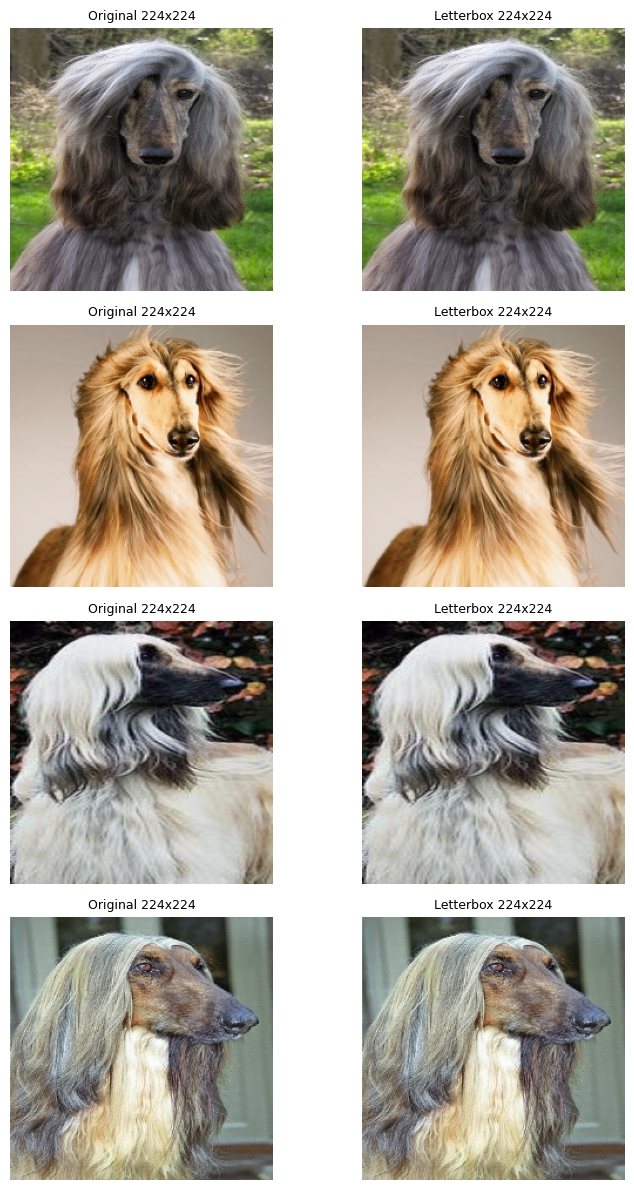

Tensor resultante: (3, 224, 224) torch.float32 min/max: -2.12 2.64


In [30]:
from lib.preprocessing import IMAGENET_MEAN, IMAGENET_STD, bgr_to_rgb, letterbox_rgb, preprocess_bgr

sample_paths = df_qc[df_qc["discard_reason"] == ""].head(4)["path"].tolist()
fig, axes = plt.subplots(len(sample_paths), 2, figsize=(8, 3 * len(sample_paths)))
for i, p in enumerate(sample_paths):
    bgr = cv2.imread(str(p))
    rgb = bgr_to_rgb(bgr)
    boxed = letterbox_rgb(rgb, target_size=settings.image_size)
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Original {rgb.shape[1]}x{rgb.shape[0]}", fontsize=9)
    axes[i, 0].axis("off")
    axes[i, 1].imshow(boxed)
    axes[i, 1].set_title(f"Letterbox {boxed.shape[1]}x{boxed.shape[0]}", fontsize=9)
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

t = preprocess_bgr(cv2.imread(str(sample_paths[0])), image_size=settings.image_size)
print("Tensor resultante:", tuple(t.shape), t.dtype, "min/max:", round(float(t.min()), 2), round(float(t.max()), 2))

## 10. Data Augmentation (solo sobre `train`)

Pipeline definido en `lib.preprocessing.build_train_augmenter` aplicado **on-the-fly** únicamente al split `train`:
- `HorizontalFlip(p=0.5)`: invariancia izquierda/derecha natural.
- `Affine(scale=(0.9, 1.1), translate=(-5%, +5%), rotate=±15°, p=0.7)`: variaciones realistas de encuadre sin rotaciones antinaturales de 90° ni flips verticales.
- `RandomBrightnessContrast(±0.2, p=0.6)` y `HueSaturationValue` acotado (`p=0.3`): robustez ante iluminación sin alterar el pelaje característico de la raza.
- `GaussianBlur(p=0.25)` y `GaussNoise(p=0.35)`: simula desenfoque de movimiento/foco y ruido de sensor.

Para mitigar el desbalance en `train` sin contaminar la galería de Etapa 1 ni duplicar archivos en disco, se combina augmentation on-the-fly con **pesos inversos por clase en `CrossEntropyLoss`** (`USE_CLASS_WEIGHTS=true`).

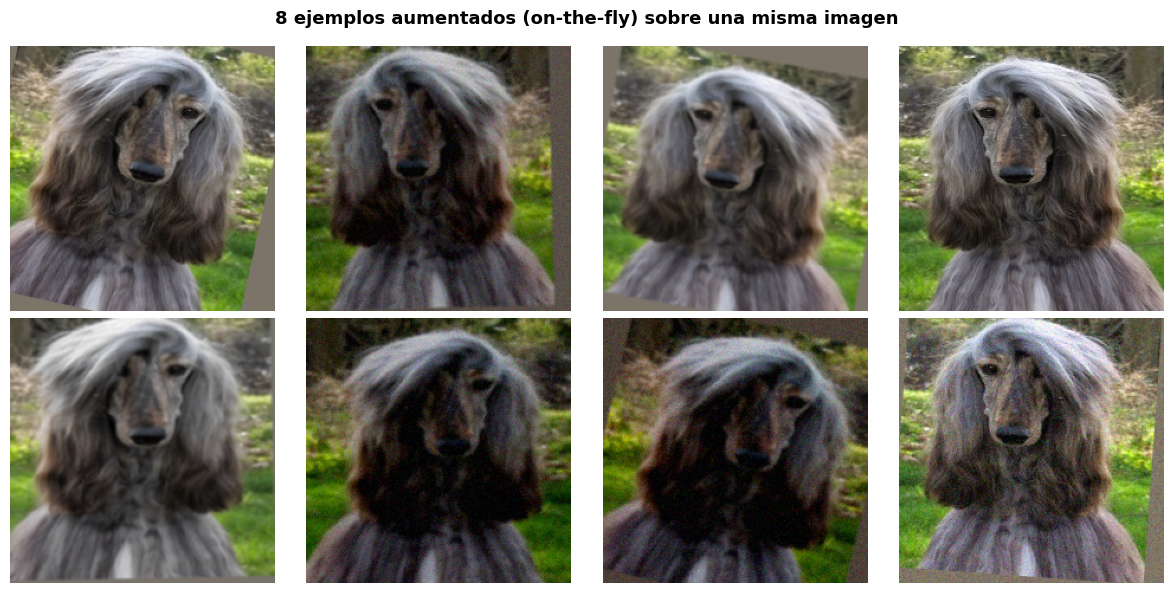

In [31]:
from lib.preprocessing import build_train_augmenter

augmenter = build_train_augmenter(seed=SEED)
demo_bgr = cv2.imread(str(sample_paths[0]))
demo_boxed = letterbox_rgb(bgr_to_rgb(demo_bgr), target_size=settings.image_size)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax in axes.flatten():
    aug_img = augmenter(image=demo_boxed)["image"]
    ax.imshow(aug_img)
    ax.axis("off")
plt.suptitle("8 ejemplos aumentados (on-the-fly) sobre una misma imagen", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 11. Exportación de splits y verificación de ausencia de fuga de datos

In [32]:
import shutil
from lib.splits import SplitSample, save_splits

kept = df_qc[df_qc["discard_reason"] == ""].copy()

# Verificacion explicita de cero fuga de datos por SHA256 entre splits
sha_by_split = {s: set(kept.loc[kept["split"] == s, "sha256"]) for s in ("train", "valid", "test")}
assert len(sha_by_split["train"] & sha_by_split["valid"]) == 0, "Fuga train-valid"
assert len(sha_by_split["train"] & sha_by_split["test"]) == 0, "Fuga train-test"
assert len(sha_by_split["valid"] & sha_by_split["test"]) == 0, "Fuga valid-test"
print("Verificacion de fuga de datos: 0 intersecciones entre train/valid/test.")

final_samples = [
    SplitSample(rel_path=row.rel_path, breed=row.breed, split=row.split)
    for row in kept.sort_values(["split", "breed", "rel_path"]).itertuples(index=False)
]
save_splits(final_samples, settings.splits_path)

if USE_DRIVE:
    shutil.copy2(settings.splits_path, DRIVE_DIR / "splits.csv")
    print("Copiado splits.csv a Google Drive:", DRIVE_DIR / "splits.csv")

Verificacion de fuga de datos: 0 intersecciones entre train/valid/test.
Copiado splits.csv a Google Drive: /content/drive/MyDrive/TP2_Perros/splits.csv


## 12. Tabla resumen final

In [33]:
summary = kept.groupby("split")["breed"].agg(imagenes="count", razas="nunique").reindex(["train", "valid", "test"])
if not df_indep.empty:
    indep_row = pd.DataFrame(
        {"imagenes": [len(df_indep)], "razas": [df_indep.loc[df_indep["group"] == "single_dog", "breed"].nunique()]},
        index=["independent"],
    )
    summary = pd.concat([summary, indep_row])
display(summary)

,imagenes,razas
train,7729,70
valid,687,70
test,696,70
independent,157,25


## 13. Licencias y uso de imágenes

- **Dataset principal:** *70 Dog Breeds Image Dataset* (Kaggle, uso académico/investigación bajo los términos publicados por el autor en Kaggle).
- **Conjunto independiente:** cada imagen se documenta con su URL de origen y licencia en `data/independent_sources.csv`.
- **Privacidad:** en escenas complejas con personas, se evita incluir rostros claramente identificables o publicar las imágenes en el repositorio.